# Setup

In [1]:
!apt-get update
!apt-get install -y poppler-utils
!pip install torch torchvision transformers pdf2image pillow timm easyocr opencv-python-headless matplotlib datasets sentencepiece


Hit:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Hit:3 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:4 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Hit:5 https://packages.cloud.google.com/apt gcsfuse-jammy InRelease
Get:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:7 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Get:10 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [2,653 kB]
Get:11 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease [24.3 kB]
Hit:12 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:13 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [8,665 kB]
Get

# PDF to Image conversion

In [2]:
import os.path
from pdf2image import convert_from_path

# Convert PDF to an image
pdf_path = "/content/2025-01-07.pdf"  # Replace with your file path
images = convert_from_path(pdf_path, dpi=300)  # Convert at 300 DPI for clarity

# Save the first page as an image
images[0].save("/content/sample_page.png", "PNG")
print("PDF page saved as image.")

PDF page saved as image.


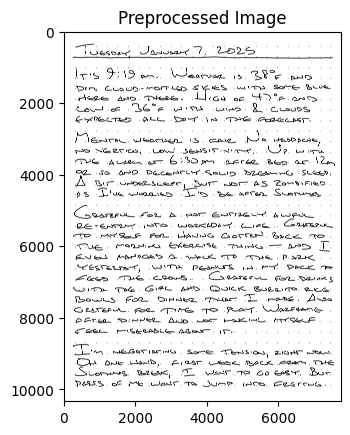

In [3]:
from PIL import Image

# Load your handwriting image
image_path = "/content/sample_page.png"
image = Image.open(image_path).convert("RGB")  # Convert to RGB (required by TrOCR)

import matplotlib.pyplot as plt
plt.imshow(image, cmap="gray")
plt.title("Preprocessed Image")
plt.show()


# Attempting to filter out the grey dot-grid

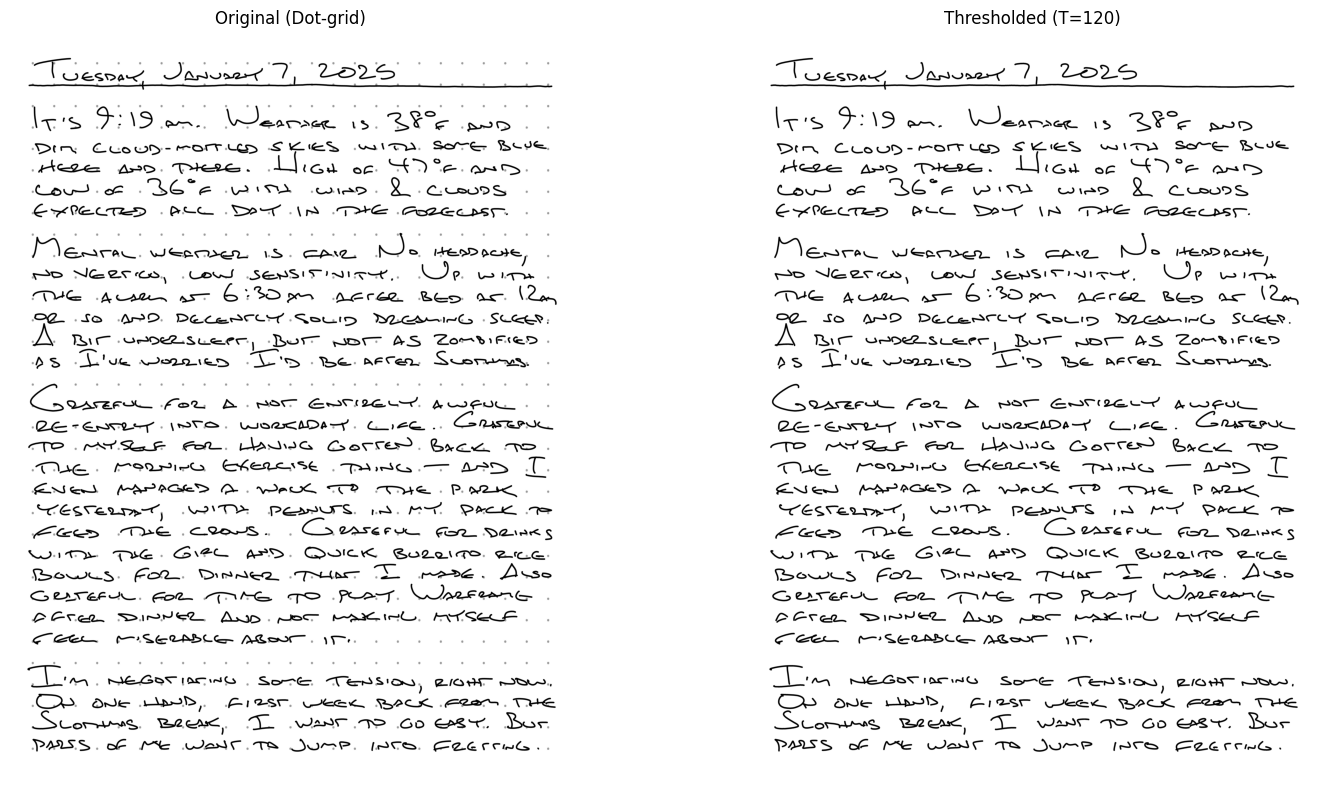

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1) Load the original image (with dot-grid background)
image_path = "/content/sample_page.png"  # Adjust path as needed
image_bgr = cv2.imread(image_path)
if image_bgr is None:
    raise ValueError("Could not load image. Check the path or filename.")

# Convert to grayscale for easier processing
image_gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# 2) Apply threshold
#    - If your handwriting is quite dark, you can use a threshold ~150-180
#      so that the lighter dots get filtered out.
thresh_value = 120
_, thresh = cv2.threshold(image_gray, thresh_value, 255, cv2.THRESH_BINARY)


cv2.imwrite("/content/my_journal_page_thresholded.png", thresh)

# 3) Morphological opening to remove small dots
#    - If the dot size is small, a small kernel (2x2, 3x3) may help.
#kernel = np.ones((12, 12), np.uint8)
#opened = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)

# 4) Display the results side by side in Colab

# Convert the original BGR image to RGB for display
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Original image
axes[0].imshow(image_rgb)
axes[0].set_title("Original (Dot-grid)")
axes[0].axis("off")

# Thresholded image
axes[1].imshow(thresh, cmap="gray")
axes[1].set_title(f"Thresholded (T={thresh_value})")
axes[1].axis("off")

# Opened image
#axes[2].imshow(opened, cmap="gray")
#axes[2].set_title("After Morphological Opening")
#axes[2].axis("off")

plt.tight_layout()
plt.show()


# Try pytesseract to find bounding boxes

In [11]:
!apt-get install -y tesseract-ocr
!pip install -q pytesseract opencv-python matplotlib numpy


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  tesseract-ocr-eng tesseract-ocr-osd
The following NEW packages will be installed:
  tesseract-ocr tesseract-ocr-eng tesseract-ocr-osd
0 upgraded, 3 newly installed, 0 to remove and 118 not upgraded.
Need to get 4,816 kB of archives.
After this operation, 15.6 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 tesseract-ocr-eng all 1:4.00~git30-7274cfa-1.1 [1,591 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 tesseract-ocr-osd all 1:4.00~git30-7274cfa-1.1 [2,990 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 tesseract-ocr amd64 4.1.1-2.1build1 [236 kB]
Fetched 4,816 kB in 2s (2,977 kB/s)
Selecting previously unselected package tesseract-ocr-eng.
(Reading database ... 123766 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr

In [36]:
import cv2
import pytesseract
import matplotlib.pyplot as plt

# Load your image
image_path = "/content/my_journal_page_thresholded.png"
image = cv2.imread(image_path)

# Get dimensions
height, width, _ = image.shape  # (height, width, channels)

# Print dimensions
print(f"Image dimensions: {width}x{height} (width x height)")

# Convert to grayscale (Tesseract works best with clean grayscale input)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

Image dimensions: 7751x10334 (width x height)


In [37]:
# Run Tesseract in layout analysis mode (returns bounding boxes)
custom_oem_psm_config = r'--oem 1 --psm 6'

# Get bounding boxes as a Pandas DataFrame
import pandas as pd
from pytesseract import Output

detection_data = pytesseract.image_to_data(gray, config=custom_oem_psm_config, output_type=Output.DICT)

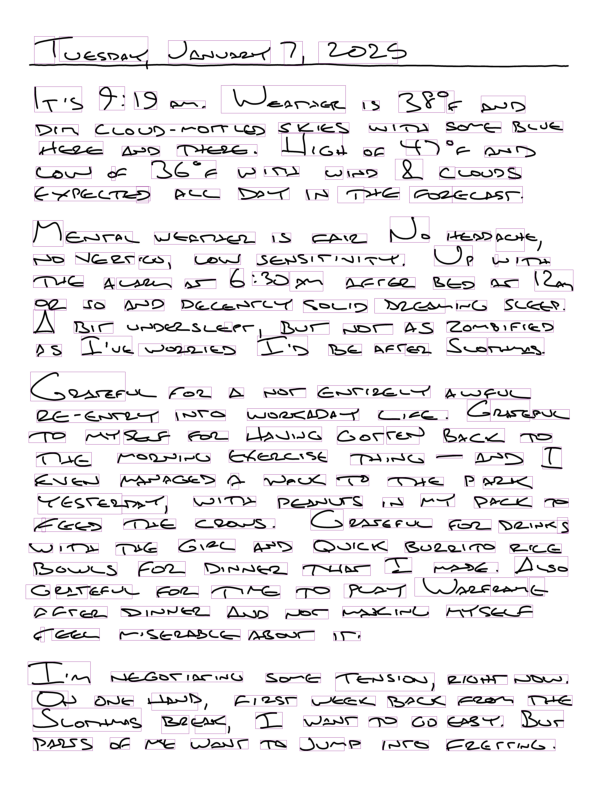

In [38]:
# Convert to DataFrame
df = pd.DataFrame(detection_data)
df = df[df['text'].str.strip() != ""]  # Remove empty detections

# Show detected bounding boxes
import numpy as np

def draw_boxes(image, df):
    if df.empty:
        print("⚠️ No text detected, skipping bounding box drawing.")
        return image  # Return original image without drawing

    image_copy = image.copy()
    for i in df.index:  # Use df.index instead of range(len(df))
        (x, y, w, h) = (df["left"][i], df["top"][i], df["width"][i], df["height"][i])
        cv2.rectangle(image_copy, (x, y), (x + w, y + h), (128, 0, 128), 2)

    return image_copy

# Draw bounding boxes
boxed_image = draw_boxes(image, df)

# Display result
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(boxed_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


# Try merging bounding boxes for words into lines

Detected 28 text lines:
(325, 354, 5199, 793)
(328, 1013, 6908, 1590)
(342, 1491, 7415, 1707)
(389, 1646, 6933, 2155)
(348, 2001, 6858, 2416)
(328, 2367, 6873, 2630)
(307, 2775, 6899, 3354)
(312, 3163, 7243, 3590)
(312, 3469, 7552, 3895)
(333, 3870, 7441, 4094)
(312, 4022, 7289, 4529)
(352, 4374, 7162, 4771)
(275, 4857, 6984, 5473)
(360, 5230, 7503, 5665)
(252, 5590, 7269, 5920)
(351, 5864, 7397, 6265)
(331, 6216, 7008, 6484)
(373, 6488, 7490, 6833)
(321, 6703, 7492, 7126)
(253, 7101, 7395, 7341)
(314, 7333, 7482, 7708)
(212, 7618, 7171, 7990)
(322, 7985, 7011, 8211)
(411, 8282, 4699, 8539)
(240, 8746, 7483, 9234)
(294, 9139, 7539, 9453)
(307, 9368, 7423, 9799)
(310, 9763, 7311, 9980)


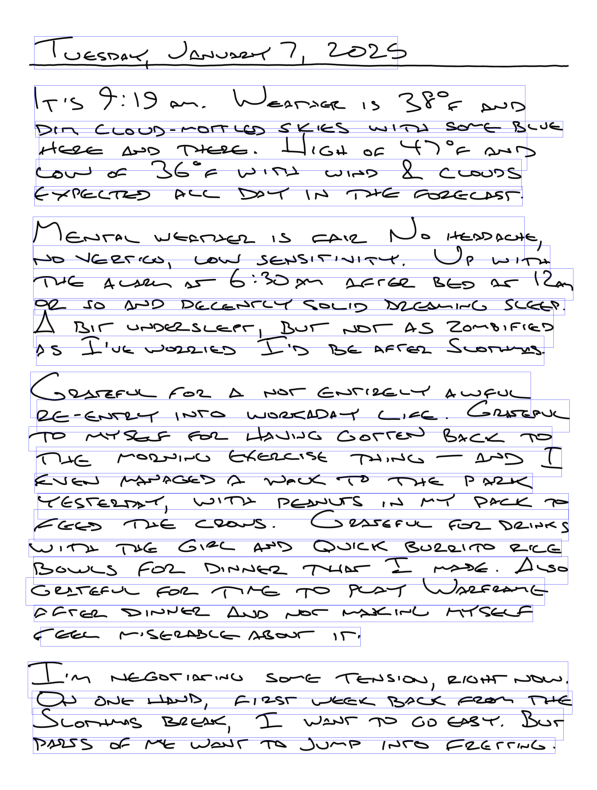

In [39]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

def refined_text_line_segmentation(df, image, peak_prominence_factor=0.01, peak_distance_factor=0.02):
    """
    Detects text lines using peak detection on the Y-histogram to prevent multi-line merging.

    Fixes:
    - Uses `find_peaks` to detect **true line positions** in the Y-histogram.
    - Prevents multi-line merging by segmenting lines based on peaks.
    - Dynamically adjusts segmentation based on detected text density.

    Args:
        df (DataFrame): Word bounding boxes from Tesseract.
        image (np.array): The original image.
        peak_prominence_factor (float): Controls how prominent a text line must be in the histogram.
        peak_distance_factor (float): Minimum distance between detected lines (as % of image height).

    Returns:
        List of refined line bounding boxes [(x1, y1, x2, y2), ...]
    """
    if df.empty:
        print("⚠️ No words detected.")
        return []

    # Get image dimensions
    height, width = image.shape[:2]

    # Convert word bounding boxes to a binary mask
    binary_mask = np.zeros((height, width), dtype=np.uint8)
    for _, row in df.iterrows():
        x1, y1, x2, y2 = row["left"], row["top"], row["left"] + row["width"], row["top"] + row["height"]
        binary_mask[y1:y2, x1:x2] = 255  # Mark text areas

    # Compute vertical projection (sum of pixels along each row)
    y_histogram = np.sum(binary_mask, axis=1)

    # Detect peaks (actual text lines) in the Y-histogram
    peak_prominence = int(height * peak_prominence_factor)  # Dynamically adjust peak prominence
    peak_distance = int(height * peak_distance_factor)  # Minimum distance between peaks
    peaks, _ = find_peaks(y_histogram, prominence=peak_prominence, distance=peak_distance)

    # **Refine bounding box detection using detected peaks**
    line_boxes = []
    for peak_y in peaks:
        words_in_line = df[(df["top"] <= peak_y) & (df["top"] + df["height"] >= peak_y)]

        if words_in_line.empty:
            continue

        # **Fix X-boundaries to stop at actual words**
        x1 = words_in_line["left"].min()
        x2 = (words_in_line["left"] + words_in_line["width"]).max()
        y1 = words_in_line["top"].min()
        y2 = words_in_line["top"].max() + words_in_line["height"].max()

        line_boxes.append((x1, y1, x2, y2))

    return line_boxes

# Apply the ultimate algorithm
line_boxes = refined_text_line_segmentation(df, image)

# Print detected refined line bounding boxes
print(f"Detected {len(line_boxes)} text lines:")
for box in line_boxes:
    print(box)

# Draw detected lines on the image
def draw_line_boxes(image, line_boxes):
    image_copy = image.copy()

    for (x1, y1, x2, y2) in line_boxes:
        cv2.rectangle(image_copy, (x1, y1), (x2, y2), (255, 0, 0), 2)  # Blue for lines

    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

# Visualize detected lines
draw_line_boxes(image, line_boxes)


# Try producing full-width lines that do not overlap

Detected 28 text lines:
[0, 354, 7751, 993]
[0, 1013, 7751, 1471]
[0, 1491, 7751, 1626]
[0, 1646, 7751, 1981]
[0, 2001, 7751, 2347]
[0, 2367, 7751, 2755]
[0, 2775, 7751, 3143]
[0, 3163, 7751, 3449]
[0, 3469, 7751, 3850]
[0, 3870, 7751, 4002]
[0, 4022, 7751, 4354]
[0, 4374, 7751, 4837]
[0, 4857, 7751, 5210]
[0, 5230, 7751, 5570]
[0, 5590, 7751, 5844]
[0, 5864, 7751, 6196]
[0, 6216, 7751, 6468]
[0, 6488, 7751, 6683]
[0, 6703, 7751, 7081]
[0, 7101, 7751, 7313]
[0, 7333, 7751, 7598]
[0, 7618, 7751, 7965]
[0, 7985, 7751, 8262]
[0, 8282, 7751, 8726]
[0, 8746, 7751, 9119]
[0, 9139, 7751, 9348]
[0, 9368, 7751, 9743]
[0, 9763, 7751, 10254]


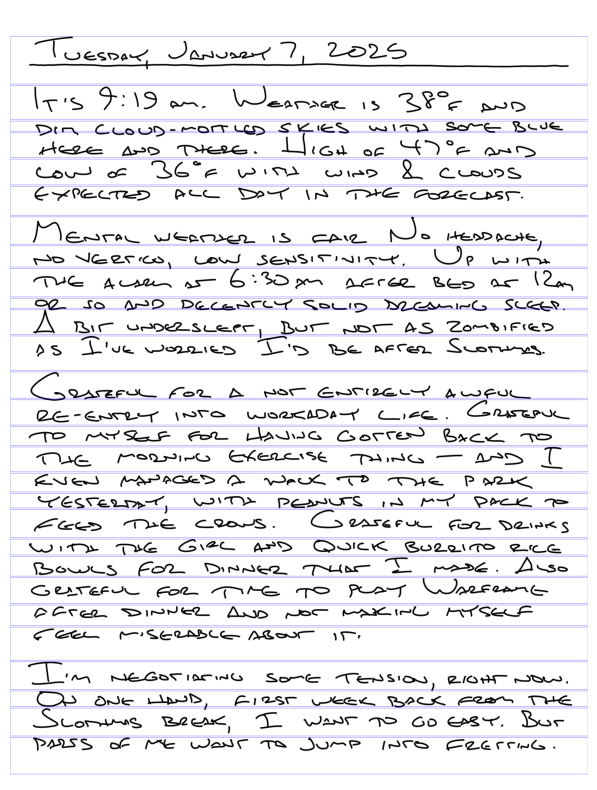

In [42]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

def final_full_width_text_line_segmentation(df, image, peak_prominence_factor=0.01, peak_distance_factor=0.02, min_spacing_factor=0.002):
    """
    Detects text lines using peak detection and ensures bounding boxes:
    - Span the full page width (X-axis).
    - Touch but do not overlap on the Y-axis.

    Fixes:
    - Extends each box to cover the full width of the image.
    - Prevents cutting off descenders by dynamically setting Y2.
    - Adjusts last line separately to allow full height extension.

    Args:
        df (DataFrame): Word bounding boxes from Tesseract.
        image (np.array): The original image.
        peak_prominence_factor (float): How prominent a text line must be in the histogram.
        peak_distance_factor (float): Minimum distance between detected lines (as % of image height).
        min_spacing_factor (float): Minimum spacing between lines (as % of image height).

    Returns:
        List of adjusted line bounding boxes [(x1, y1, x2, y2), ...]
    """
    if df.empty:
        print("⚠️ No words detected.")
        return []

    # Get image dimensions
    height, width = image.shape[:2]

    # Convert word bounding boxes to a binary mask
    binary_mask = np.zeros((height, width), dtype=np.uint8)
    for _, row in df.iterrows():
        x1, y1, x2, y2 = row["left"], row["top"], row["left"] + row["width"], row["top"] + row["height"]
        binary_mask[y1:y2, x1:x2] = 255  # Mark text areas

    # Compute vertical projection (sum of pixels along each row)
    y_histogram = np.sum(binary_mask, axis=1)

    # Detect peaks (actual text lines) in the Y-histogram
    peak_prominence = int(height * peak_prominence_factor)  # Dynamically adjust peak prominence
    peak_distance = int(height * peak_distance_factor)  # Minimum distance between peaks
    peaks, _ = find_peaks(y_histogram, prominence=peak_prominence, distance=peak_distance)

    # **Determine line heights dynamically**
    detected_heights = [
        df[(df["top"] <= peak_y) & (df["top"] + df["height"] >= peak_y)]["height"].max() for peak_y in peaks
    ]
    median_line_height = int(np.median(detected_heights)) if detected_heights else 20  # Default if empty
    min_spacing = int(height * min_spacing_factor)  # Smallest allowable gap between lines

    # **Store initial bounding boxes before adjusting Y2**
    raw_line_boxes = []
    for i, peak_y in enumerate(peaks):
        words_in_line = df[(df["top"] <= peak_y) & (df["top"] + df["height"] >= peak_y)]
        if words_in_line.empty:
            continue

        # **Set X-bounds to full width**
        x1 = 0  # Start from the left edge of the page
        x2 = width  # Extend to the right edge of the page

        # **Set Y1 and initial Y2 before adjustment**
        y1 = words_in_line["top"].min()
        y2 = words_in_line["top"].max() + words_in_line["height"].max()

        raw_line_boxes.append([x1, y1, x2, y2])  # Store mutable list

    # **Adjust Y2 of each line to match the next line’s Y1**
    for i in range(len(raw_line_boxes) - 1):
        raw_line_boxes[i][3] = raw_line_boxes[i + 1][1] - min_spacing  # Y2 of current = Y1 of next - spacing

    # Ensure last line extends fully
    raw_line_boxes[-1][3] = min(height, raw_line_boxes[-1][3] + median_line_height)

    return raw_line_boxes

# Apply the final refined algorithm
line_boxes = final_full_width_text_line_segmentation(df, image)

# Print detected refined line bounding boxes
print(f"Detected {len(line_boxes)} text lines:")
for box in line_boxes:
    print(box)

# Draw detected lines on the image
def draw_line_boxes(image, line_boxes):
    image_copy = image.copy()

    for (x1, y1, x2, y2) in line_boxes:
        cv2.rectangle(image_copy, (x1, y1), (x2, y2), (255, 0, 0), 2)  # Blue for lines

    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

# Visualize detected lines
draw_line_boxes(image, line_boxes)


# Try producing full-width lines that may overlap

Detected 28 text lines:
(0, 354, 7751, 793)
(0, 1013, 7751, 1590)
(0, 1491, 7751, 1707)
(0, 1646, 7751, 2155)
(0, 2001, 7751, 2416)
(0, 2367, 7751, 2630)
(0, 2775, 7751, 3354)
(0, 3163, 7751, 3590)
(0, 3469, 7751, 3895)
(0, 3870, 7751, 4094)
(0, 4022, 7751, 4529)
(0, 4374, 7751, 4771)
(0, 4857, 7751, 5473)
(0, 5230, 7751, 5665)
(0, 5590, 7751, 5920)
(0, 5864, 7751, 6265)
(0, 6216, 7751, 6484)
(0, 6488, 7751, 6833)
(0, 6703, 7751, 7126)
(0, 7101, 7751, 7341)
(0, 7333, 7751, 7708)
(0, 7618, 7751, 7990)
(0, 7985, 7751, 8211)
(0, 8282, 7751, 8539)
(0, 8746, 7751, 9234)
(0, 9139, 7751, 9453)
(0, 9368, 7751, 9799)
(0, 9763, 7751, 9980)


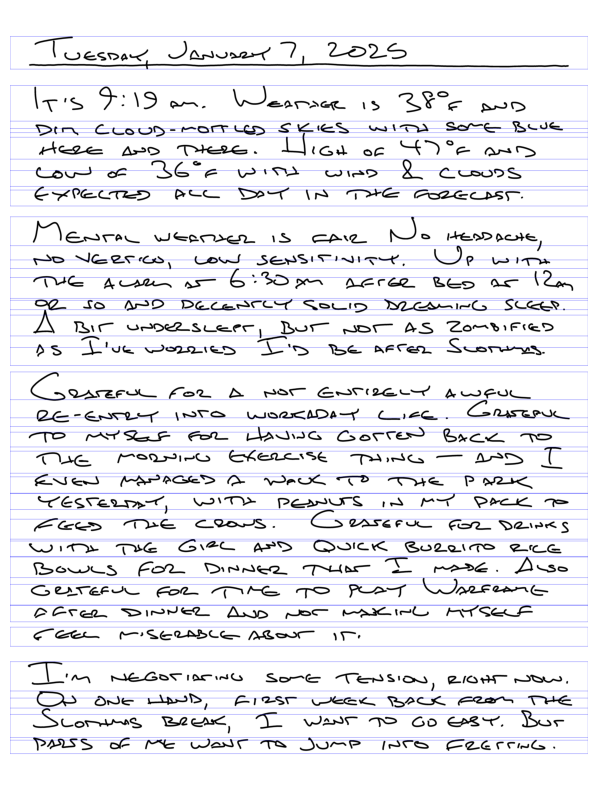

In [41]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

def full_width_overlapping_lines(df, image, peak_prominence_factor=0.01, peak_distance_factor=0.02):
    """
    Detects text lines using peak detection and allows overlapping Y-boundaries.
    - Each line spans the full page width (X-axis).
    - Allows Y-overlap between lines.

    Args:
        df (DataFrame): Word bounding boxes from Tesseract.
        image (np.array): The original image.
        peak_prominence_factor (float): How prominent a text line must be in the histogram.
        peak_distance_factor (float): Minimum distance between detected lines (as % of image height).

    Returns:
        List of adjusted line bounding boxes [(x1, y1, x2, y2), ...]
    """
    if df.empty:
        print("⚠️ No words detected.")
        return []

    # Get image dimensions
    height, width = image.shape[:2]

    # Convert word bounding boxes to a binary mask
    binary_mask = np.zeros((height, width), dtype=np.uint8)
    for _, row in df.iterrows():
        x1, y1, x2, y2 = row["left"], row["top"], row["left"] + row["width"], row["top"] + row["height"]
        binary_mask[y1:y2, x1:x2] = 255  # Mark text areas

    # Compute vertical projection (sum of pixels along each row)
    y_histogram = np.sum(binary_mask, axis=1)

    # Detect peaks (actual text lines) in the Y-histogram
    peak_prominence = int(height * peak_prominence_factor)  # Dynamically adjust peak prominence
    peak_distance = int(height * peak_distance_factor)  # Minimum distance between peaks
    peaks, _ = find_peaks(y_histogram, prominence=peak_prominence, distance=peak_distance)

    # **Determine line heights dynamically**
    detected_heights = [
        df[(df["top"] <= peak_y) & (df["top"] + df["height"] >= peak_y)]["height"].max() for peak_y in peaks
    ]
    median_line_height = int(np.median(detected_heights)) if detected_heights else 20  # Default if empty

    # **Store bounding boxes with full width**
    line_boxes = []
    for i, peak_y in enumerate(peaks):
        words_in_line = df[(df["top"] <= peak_y) & (df["top"] + df["height"] >= peak_y)]
        if words_in_line.empty:
            continue

        # **Set X-bounds to full width**
        x1 = 0  # Start from the left edge of the page
        x2 = width  # Extend to the right edge of the page

        # **Set Y1 and Y2 to previous overlapping behavior**
        y1 = words_in_line["top"].min()
        y2 = words_in_line["top"].max() + words_in_line["height"].max()

        line_boxes.append((x1, y1, x2, y2))

    return line_boxes

# Apply the final refined algorithm
line_boxes = full_width_overlapping_lines(df, image)

# Print detected refined line bounding boxes
print(f"Detected {len(line_boxes)} text lines:")
for box in line_boxes:
    print(box)

# Draw detected lines on the image
def draw_line_boxes(image, line_boxes):
    image_copy = image.copy()

    for (x1, y1, x2, y2) in line_boxes:
        cv2.rectangle(image_copy, (x1, y1), (x2, y2), (255, 0, 0), 2)  # Blue for lines

    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

# Visualize detected lines
draw_line_boxes(image, line_boxes)


# Try finding lines without tesseract

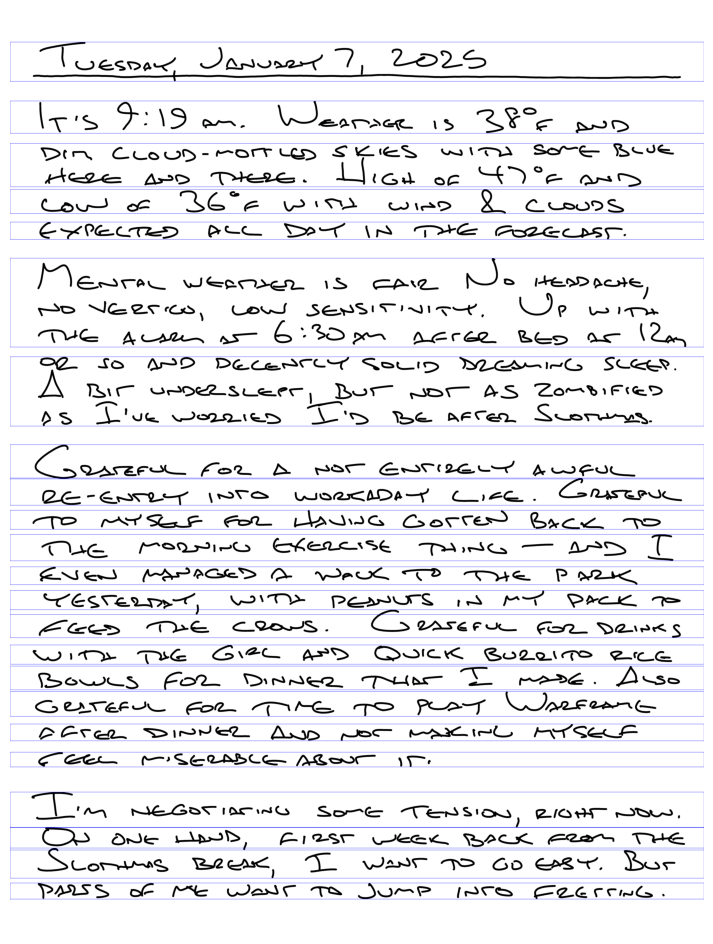

In [35]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def detect_full_width_lines(image, line_kernel_size=600):
    """
    Detects full-width text lines using whitespace analysis (no OCR, only line detection).

    Args:
        image (np.array): Input grayscale or RGB image.
        line_kernel_size (int): Size of the horizontal kernel for detecting lines.

    Returns:
        line_boxes (list of tuples): Bounding boxes of detected lines [(x1, y1, x2, y2), ...].
    """
    # Convert to grayscale if needed
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image.copy()

    # Apply adaptive thresholding (handles varying handwriting intensity)
    binary = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 2)

    ### **Step 1: Detect Lines Using Horizontal Projection**
    line_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (line_kernel_size, 1))  # Large horizontal kernel
    detected_lines = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, line_kernel, iterations=2)

    # Find contours for text lines
    line_contours, _ = cv2.findContours(detected_lines, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    line_boxes = [cv2.boundingRect(c) for c in line_contours]

    # **Step 2: Adjust Bounding Boxes to Span Full Page Width**
    height, width = image.shape[:2]  # Get image dimensions
    full_width_boxes = [(0, y, width, y + h) for (x, y, w, h) in line_boxes]  # Set x1=0, x2=width

    return full_width_boxes

# Apply detection on your image
line_boxes = detect_full_width_lines(image)

# Draw detected lines on a copy of the image
def draw_detected_lines(image, line_boxes):
    image_copy = image.copy()

    # Draw full-width line bounding boxes in **blue**
    for (x1, y1, x2, y2) in line_boxes:
        cv2.rectangle(image_copy, (x1, y1), (x2, y2), (255, 0, 0), 2)

    plt.figure(figsize=(12, 12))
    plt.imshow(cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

# Visualize detected lines
draw_detected_lines(image, line_boxes)


# Try cropping lines into separate PNGs

In [17]:
import os
import cv2

def save_cropped_lines(image, line_boxes, output_dir="cropped_lines"):
    """
    Crops each detected line from the original image and saves them as PNGs.

    Args:
        image (np.array): The original input image.
        line_boxes (list of tuples): List of (x1, y1, x2, y2) bounding boxes for detected lines.
        output_dir (str): Directory where cropped images will be saved.
    """
    # Ensure the output directory exists
    os.makedirs(output_dir, exist_ok=True)

    # Iterate through detected lines and save cropped images
    for i, (x1, y1, x2, y2) in enumerate(line_boxes):
        cropped_line = image[y1:y2, x1:x2]  # Crop the line region
        line_filename = os.path.join(output_dir, f"line_{i:03d}.png")  # Zero-padded filenames

        cv2.imwrite(line_filename, cropped_line)  # Save the cropped image

    print(f"✅ Saved {len(line_boxes)} cropped lines to '{output_dir}/'")

# Apply cropping and save the extracted lines
save_cropped_lines(image, line_boxes)


✅ Saved 28 cropped lines to 'cropped_lines/'


# Try running baseline TrOCR on the cropped lines

In [28]:
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image
import os

# Detect GPU or fallback to CPU
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using device: {device}")

# Load TrOCR model and processor
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten").to(device)

def recognize_text_from_lines(input_dir="cropped_lines"):
    """
    Runs TrOCR on each cropped line using GPU if available.

    Args:
        input_dir (str): Directory containing cropped line images.

    Returns:
        List of recognized text for each line.
    """
    recognized_texts = []
    image_files = sorted([f for f in os.listdir(input_dir) if f.endswith(".png")])  # Sort for correct order

    for img_file in image_files:
        img_path = os.path.join(input_dir, img_file)
        image = Image.open(img_path).convert("RGB")  # Convert to RGB

        # Move input to GPU
        pixel_values = processor(image, return_tensors="pt").pixel_values.to(device)

        # Run TrOCR on GPU
        with torch.no_grad():
            generated_ids = model.generate(pixel_values)

        recognized_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
        recognized_texts.append(recognized_text)

    return recognized_texts

# Run TrOCR on cropped lines with GPU acceleration
recognized_texts = recognize_text_from_lines()

# Print recognized text per line
for i, text in enumerate(recognized_texts):
    print(f"Line {i}: {text}")


Using device: cuda


Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.10/dist-packages/transformers/generation/utils.py:1220: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Line 0: Tuesday January 7 , 2025
Line 1: It's I'll I'm . Weaver is 38, and
Line 2: DIN CLOUD-MONLEY SKIES WINS SOME BUVE
Line 3: these and more . What of this man
Line 4: coat of 36"F.aint with & causes
Line 5: expected all day in the forecast .
Line 6: Mental weather is care . No , associate ,
Line 7: mongeries , now sensitivity . Up with
Line 8: THE AUSAN'S.6130 in agree Bto as 12m.
Line 9: of so and recently solid dreaming sleep .
Line 10: A bit undersizer , but not as zonified
Line 11: as I've worried I'd be after Scotties .
Line 12: General for a retirement , American
Line 13: re-entry into workaday like , General
Line 14: to myself for having gotten back to
Line 15: The morning interest think - and I
Line 16: even managed a walk to the park .
Line 17: " Yesterday , with Pennus in my pack p.
Line 18: faces the years . General for being
Line 19: with the Girl and Quick Burning Rice
Line 20: Bowls for dinner that I rose . Also
Line 21: certain for time to play Western to
Line 22: Af

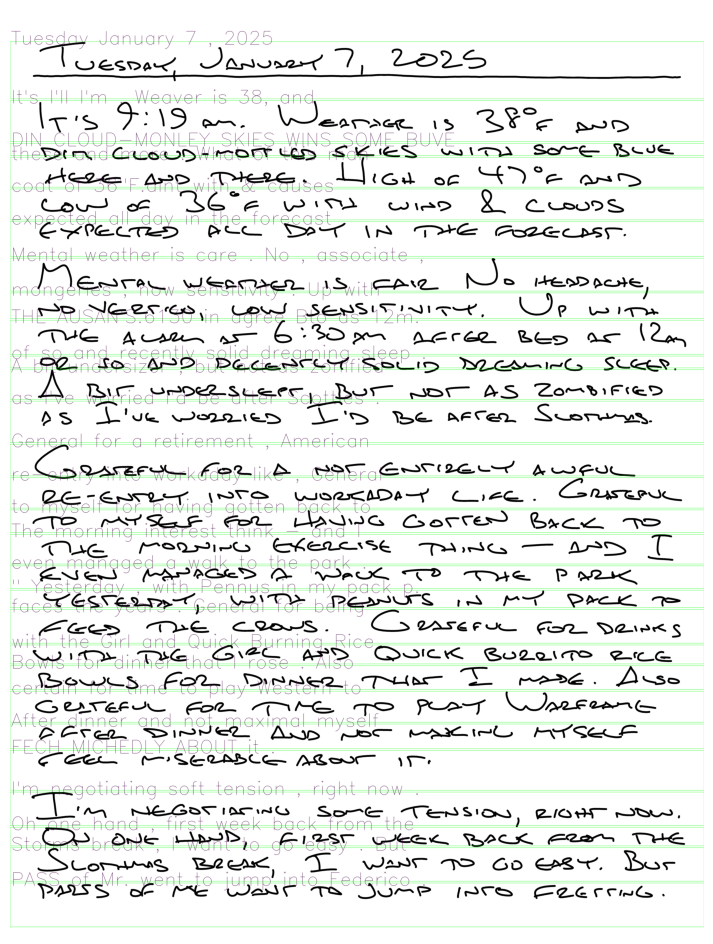

In [26]:
import cv2
import matplotlib.pyplot as plt

def overlay_text_on_image(image, line_boxes, recognized_texts):
    """
    Draws recognized text on the original image at detected line positions.

    Args:
        image (np.array): The original image.
        line_boxes (list of tuples): Bounding boxes for detected lines.
        recognized_texts (list): Recognized text for each line.

    Returns:
        Annotated image with text overlays.
    """
    image_copy = image.copy()

    for i, (x1, y1, x2, y2) in enumerate(line_boxes):
        if i >= len(recognized_texts):
            break  # Ensure no out-of-bounds issues

        text = recognized_texts[i]

        # Draw bounding box
        cv2.rectangle(image_copy, (x1, y1), (x2, y2), (0, 255, 0), 2)  # Green bounding box

        # Draw recognized text
        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 7 # max(0.5, (y2 - y1) / 50)  # Adjust font size dynamically
        thickness = 2
        text_x = x1 + 10  # Slightly inside the box
        text_y = y1 + 30  # Adjust text height for readability
        cv2.putText(image_copy, text, (text_x, text_y), font, font_scale, (64, 0, 64), thickness, cv2.LINE_AA)

    return image_copy

# Apply text overlay on image
annotated_image = overlay_text_on_image(image, line_boxes, recognized_texts)

# Display the image with recognized text
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


# Crop lines from PNG and produce CSV for training dataset

In [21]:
import os
import cv2
import csv
import torch
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

# Ensure TrOCR runs on GPU if available
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using device: {device}")

# Load TrOCR model and processor
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten").to(device)

def save_cropped_lines_and_labels(image, line_boxes, output_dir="cropped_lines", csv_filename="dataset.csv"):
    """
    Crops each detected line from the original image, saves it as a PNG, and stores recognized text in a CSV.

    Args:
        image (np.array): The original input image.
        line_boxes (list of tuples): Bounding boxes of detected lines [(x1, y1, x2, y2), ...].
        output_dir (str): Directory where cropped images will be saved.
        csv_filename (str): Output CSV file storing image filenames and recognized text.
    """
    # Ensure the output directory exists
    os.makedirs(output_dir, exist_ok=True)

    # Open CSV file for writing
    csv_path = os.path.join(output_dir, csv_filename)
    with open(csv_path, mode="w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["filename", "text"])  # CSV Header

        # Iterate through detected lines
        for i, (x1, y1, x2, y2) in enumerate(line_boxes):
            cropped_line = image[y1:y2, x1:x2]  # Crop the line region
            line_filename = f"line_{i:03d}.png"  # Zero-padded filenames
            line_path = os.path.join(output_dir, line_filename)

            # Save cropped line as PNG
            cv2.imwrite(line_path, cropped_line)

            # Convert to PIL Image for TrOCR
            cropped_pil = Image.fromarray(cv2.cvtColor(cropped_line, cv2.COLOR_BGR2RGB))

            # Run TrOCR for initial transcription
            pixel_values = processor(cropped_pil, return_tensors="pt").pixel_values.to(device)
            with torch.no_grad():
                generated_ids = model.generate(pixel_values)

            recognized_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

            # Write filename and recognized text to CSV
            writer.writerow([line_filename, recognized_text])

    print(f"✅ Saved {len(line_boxes)} cropped lines to '{output_dir}/' and created '{csv_filename}'.")

# Apply cropping, save images, and generate CSV
save_cropped_lines_and_labels(image, line_boxes)


Using device: cuda


Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.10/dist-packages/transformers/generation/utils.py:1220: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


✅ Saved 28 cropped lines to 'cropped_lines/' and created 'dataset.csv'.


# Try correcting the detected text

In [69]:
import gradio as gr
import pandas as pd
import os

# Define paths
IMAGE_DIR = "cropped_lines"  # Directory containing PNGs
CSV_FILE = os.path.join(IMAGE_DIR, "dataset.csv")  # OCR-generated CSV
OUTPUT_CSV = os.path.join(IMAGE_DIR, "corrected_dataset.csv")  # Where corrections will be saved

# Load dataset (or initialize corrections)
df = pd.read_csv(OUTPUT_CSV if os.path.exists(OUTPUT_CSV) else CSV_FILE)
df.to_csv(OUTPUT_CSV, index=False)  # Ensure a copy is saved

# Track current index
current_index = 0

# Function to get the next image
def get_next_image():
    global current_index
    if current_index >= len(df):
        return None, "", "✅ All images reviewed!"

    row = df.iloc[current_index]
    img_path = os.path.join(IMAGE_DIR, row["filename"])
    return img_path if os.path.exists(img_path) else None, row["filename"], row["text"]

# Function to save text and load the next image
def save_and_next(filename, corrected_text):
    global current_index
    if not filename:  # No more images
        return None, "", "✅ All images reviewed!"

    df.loc[df["filename"] == filename, "text"] = corrected_text
    df.to_csv(OUTPUT_CSV, index=False)

    current_index += 1
    return get_next_image()  # Load next image

# Load the first image at startup
img_path, filename, text = get_next_image()

# Create Gradio UI
with gr.Blocks() as demo:
    gr.Markdown("## 📝 Review & Correct OCR Predictions")

    with gr.Row():
        img_display = gr.Image(type="filepath", value=img_path, show_label=False, interactive=False, height=100)

    text_input = gr.Textbox(value=text, label="Corrected Text", interactive=True)
    filename_tracker = gr.Textbox(value=filename, visible=False)  # Hidden tracker
    save_button = gr.Button("✅ Save & Next")

    # **Trigger "Save & Next" on pressing Enter in the text field**
    text_input.submit(fn=save_and_next, inputs=[filename_tracker, text_input], outputs=[img_display, filename_tracker, text_input])

    # **Clicking "Save & Next" updates the UI**
    save_button.click(fn=save_and_next, inputs=[filename_tracker, text_input], outputs=[img_display, filename_tracker, text_input])


# Launch Gradio UI
demo.launch()


Running Gradio in a Colab notebook requires sharing enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dcef777958cb3f718f.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Finetune TrOCR from the corrected dataset

In [74]:
import torch
import pandas as pd
import os
from datasets import Dataset, DatasetDict
from transformers import TrOCRProcessor, VisionEncoderDecoderModel, Seq2SeqTrainer, Seq2SeqTrainingArguments
from PIL import Image
from torchvision import transforms
from sklearn.model_selection import train_test_split

# **PARAMETERS**
IMAGE_DIR = "cropped_lines"  # Directory containing PNGs
CSV_FILE = os.path.join(IMAGE_DIR, "corrected_dataset.csv")  # Corrected OCR labels
MODEL_OUTPUT_DIR = "./trocr_finetuned_attempt_1"  # Change for different runs
TRAIN_SPLIT = 0.9  # 90% training, 10% validation

# Ensure output directory exists
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

# Load dataset from CSV
df = pd.read_csv(CSV_FILE)

# Ensure dataset is not empty
if df.empty:
    raise ValueError("❌ The dataset CSV is empty! Please check your data.")

# **Step 1: Split Dataset into Training & Validation**
train_df, val_df = train_test_split(df, train_size=TRAIN_SPLIT, random_state=42)

# Convert to Hugging Face Dataset
train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)

# Create DatasetDict
dataset = DatasetDict({"train": train_dataset, "validation": val_dataset})

# **Step 2: Preprocess Images**
# Define image transformation
image_transforms = transforms.Compose([
    transforms.Resize((384, 384)),  # Resize for TrOCR input
    transforms.ToTensor()
])

# Function to load images and text
def preprocess_data(example):
    img_path = os.path.join(IMAGE_DIR, example["filename"])
    if not os.path.exists(img_path):
        raise FileNotFoundError(f"❌ Missing image file: {img_path}")

    # Load and transform image
    image = Image.open(img_path).convert("RGB")
    pixel_values = image_transforms(image)

    return {"pixel_values": pixel_values, "text": example["text"]}

# Apply preprocessing
dataset = dataset.map(preprocess_data, remove_columns=["filename"])

# **Step 3: Load Pretrained TrOCR**
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten")

# **Ensure `decoder_start_token_id` is set**
if model.config.decoder_start_token_id is None:
    model.config.decoder_start_token_id = processor.tokenizer.eos_token_id
    print(f"✅ `decoder_start_token_id` set to eos_token_id: {model.config.decoder_start_token_id}")
else:
    print(f"✅ `decoder_start_token_id` is already set: {model.config.decoder_start_token_id}")

# **Ensure `pad_token_id` is set**
if processor.tokenizer.pad_token is None:
    processor.tokenizer.add_special_tokens({'pad_token': '<PAD>'})
    model.resize_token_embeddings(len(processor.tokenizer))
    print("✅ Added `pad_token`: <PAD>")
else:
    print(f"✅ `pad_token` already defined: {processor.tokenizer.pad_token}")

# Set the padding token ID in model configuration
model.config.pad_token_id = processor.tokenizer.pad_token_id
model.config.labels_pad_token_id = processor.tokenizer.pad_token_id

print(f"✅ `pad_token_id` set to: {model.config.pad_token_id}")
print(f"✅ `labels_pad_token_id` set to: {model.config.labels_pad_token_id}")

# Tokenize text labels
def tokenize_labels(example):
    labels = processor.tokenizer(example["text"], padding="max_length", truncation=True, max_length=128).input_ids
    example["labels"] = labels
    return example

dataset = dataset.map(tokenize_labels, remove_columns=["text"])

# **Step 4: Fine-Tune TrOCR with Training & Validation Data**
training_args = Seq2SeqTrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    per_device_train_batch_size=4,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    num_train_epochs=5,
    save_total_limit=2,
    logging_dir=os.path.join(MODEL_OUTPUT_DIR, "logs"),
    logging_steps=50,
    learning_rate=5e-5,
    weight_decay=0.01,
    report_to="none",  # Prevents unnecessary logging
    eval_steps=500,
    save_steps=1000,
    predict_with_generate=True
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    tokenizer=processor.feature_extractor,  # Required for image data
)

# **Start Training**
trainer.train()

# **Save Fine-Tuned Model**
model.save_pretrained(MODEL_OUTPUT_DIR)
processor.save_pretrained(MODEL_OUTPUT_DIR)

print(f"✅ Fine-tuning complete! Model saved in '{MODEL_OUTPUT_DIR}'.")


Map:   0%|          | 0/25 [00:00<?, ? examples/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ `decoder_start_token_id` set to eos_token_id: 2
✅ `pad_token` already defined: <pad>
✅ `pad_token_id` set to: 1
✅ `labels_pad_token_id` set to: 1


Map:   0%|          | 0/25 [00:00<?, ? examples/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

/usr/local/lib/python3.10/dist-packages/transformers/training_args.py:1545: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/transformers/models/trocr/processing_trocr.py:137: FutureWarning: `feature_extractor` is deprecated and will be removed in v5. Use `image_processor` instead.
  warnings.warn(


Epoch,Training Loss,Validation Loss
1,No log,0.674217
2,No log,0.334766
3,No log,0.596076
4,No log,0.321906
5,No log,0.265699


✅ Fine-tuning complete! Model saved in './trocr_finetuned_attempt_1'.


# Compare baseline vs finetuned TrOCR

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.10/dist-packages/transformers/generation/utils.py:1220: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


📊 **Baseline vs. Fine-Tuned Metrics:**
🔹 Character Error Rate (CER): 0.6044
🔹 Word Error Rate (WER): 0.9075


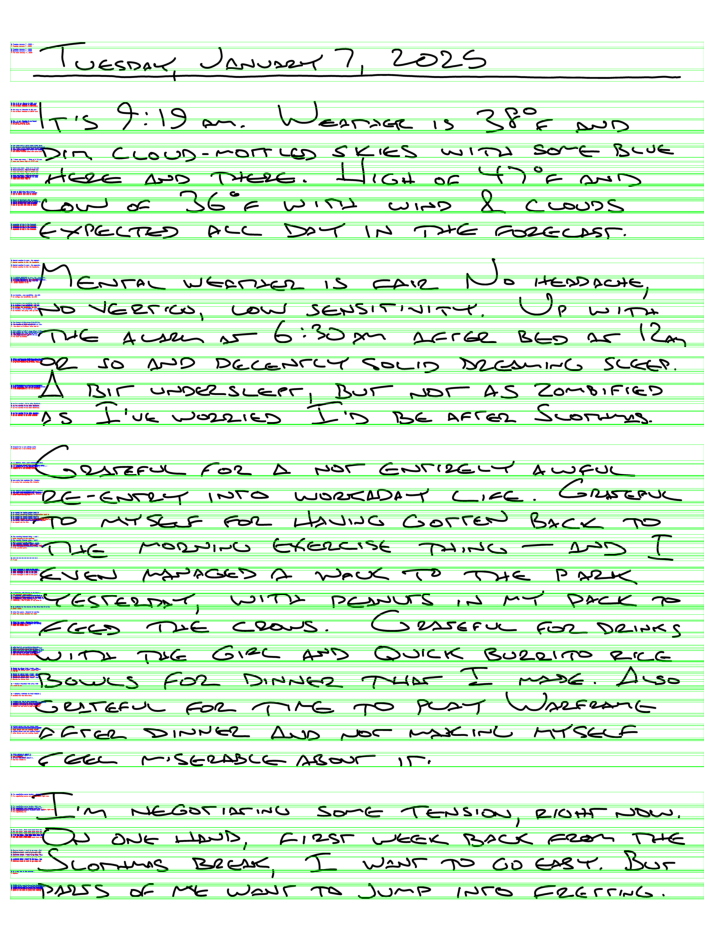

✅ Annotated comparison image saved as 'comparison_journal.png'


In [77]:
import torch
import os
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
import evaluate  # ✅ Replaces deprecated load_metric()

# **PARAMETERS**
BASELINE_MODEL_PATH = "microsoft/trocr-base-handwritten"  # Hugging Face baseline model
FINETUNED_MODEL_PATH = "./trocr_finetuned_attempt_1"  # Your fine-tuned model directory
JOURNAL_PAGE_PATH = "my_journal_page_thresholded.png"  # The full journal page PNG
OUTPUT_IMAGE_PATH = "comparison_journal.png"  # Where the annotated image will be saved

# **Step 1: Load Both Models**
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load baseline model
processor_baseline = TrOCRProcessor.from_pretrained(BASELINE_MODEL_PATH)
model_baseline = VisionEncoderDecoderModel.from_pretrained(BASELINE_MODEL_PATH).to(device)

# Load fine-tuned model
processor_finetuned = TrOCRProcessor.from_pretrained(FINETUNED_MODEL_PATH)
model_finetuned = VisionEncoderDecoderModel.from_pretrained(FINETUNED_MODEL_PATH).to(device)

# **Step 2: Detect Lines Using Whitespace-Based Method**
def detect_lines_by_whitespace(image, line_kernel_size=100):
    """Detects text lines using horizontal whitespace projection."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    binary = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 2)

    # Detect lines
    line_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (line_kernel_size, 1))
    detected_lines = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, line_kernel, iterations=2)

    # Find contours
    contours, _ = cv2.findContours(detected_lines, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    line_boxes = [cv2.boundingRect(c) for c in contours]

    # Convert to full-width bounding boxes
    height, width = image.shape[:2]
    full_width_boxes = [(0, y, width, y + h) for (x, y, w, h) in line_boxes]

    return sorted(full_width_boxes, key=lambda box: box[1])  # Sort lines top-to-bottom

# Load the journal page
image = cv2.imread(JOURNAL_PAGE_PATH)
line_boxes = detect_lines_by_whitespace(image)

# **Step 3: Run Both Models on Each Line**
def recognize_text_from_line(image, line_box, processor, model):
    """Runs OCR on a cropped line from the journal page."""
    x1, y1, x2, y2 = line_box
    cropped_line = image[y1:y2, x1:x2]
    cropped_pil = Image.fromarray(cv2.cvtColor(cropped_line, cv2.COLOR_BGR2RGB))

    # Run TrOCR
    pixel_values = processor(cropped_pil, return_tensors="pt").pixel_values.to(device)
    with torch.no_grad():
        generated_ids = model.generate(pixel_values)

    return processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

baseline_outputs = []
finetuned_outputs = []

for line_box in line_boxes:
    baseline_text = recognize_text_from_line(image, line_box, processor_baseline, model_baseline)
    finetuned_text = recognize_text_from_line(image, line_box, processor_finetuned, model_finetuned)

    baseline_outputs.append(baseline_text)
    finetuned_outputs.append(finetuned_text)

# **Step 4: Compute CER & WER Using `evaluate` Library**
cer_metric = evaluate.load("cer")
wer_metric = evaluate.load("wer")

cer_baseline = cer_metric.compute(predictions=baseline_outputs, references=finetuned_outputs)
wer_baseline = wer_metric.compute(predictions=baseline_outputs, references=finetuned_outputs)

print(f"📊 **Baseline vs. Fine-Tuned Metrics:**")
print(f"🔹 Character Error Rate (CER): {cer_baseline:.4f}")
print(f"🔹 Word Error Rate (WER): {wer_baseline:.4f}")



B: Tuesday January 7 , 2025 -
F: Tuesday January 7 , 2025
B: Tuesday January 7 , 2025
F: AF
B: Tuesday January 7 , 2025
F: I've want January 7 , 2025
B: It's # 19 on. Weaver is 380, and
F: It's 9:19am. Weather is RRF and
B: It's 9.19 on. Weaver is 380, and
F: It's 9:19am. Weather is RRF and
B: It's 9.19 on. Weaver is 38. and
F: It's 9:19am. Weather is 38°F and
B: It's truly an. Weander is 38. and
F: It's 9:19am. Weather is 38°F and
B: it's , I.I am. Weapier is so found
F: It's 9am. Weather is so
B: it's , I.I am. Weather is so found
F: It's 9am. Weather is so
B: M.S.P.P.P. . " P.P.P.C
F: I'd be want to be warm.
B: DIN CINN-NOTLY SICKS WIND SOME BUVE
F: I'm going forward sides with some blue
B: DIN CLOUD-MONTER SKIES WINS SOME BUVE .
F: dim cloud-mottled skies with some blue
B: din ( Iain-women SICKS WIND SOME ONE .
F: I'm going forward.
B: 7DIN CLOUD-MONTLED SKIES W.D. SOME D.
F: dim cloud-mottled skies with some dive
B: " there was more . " What of 4 )'d own
F: here and there. High of

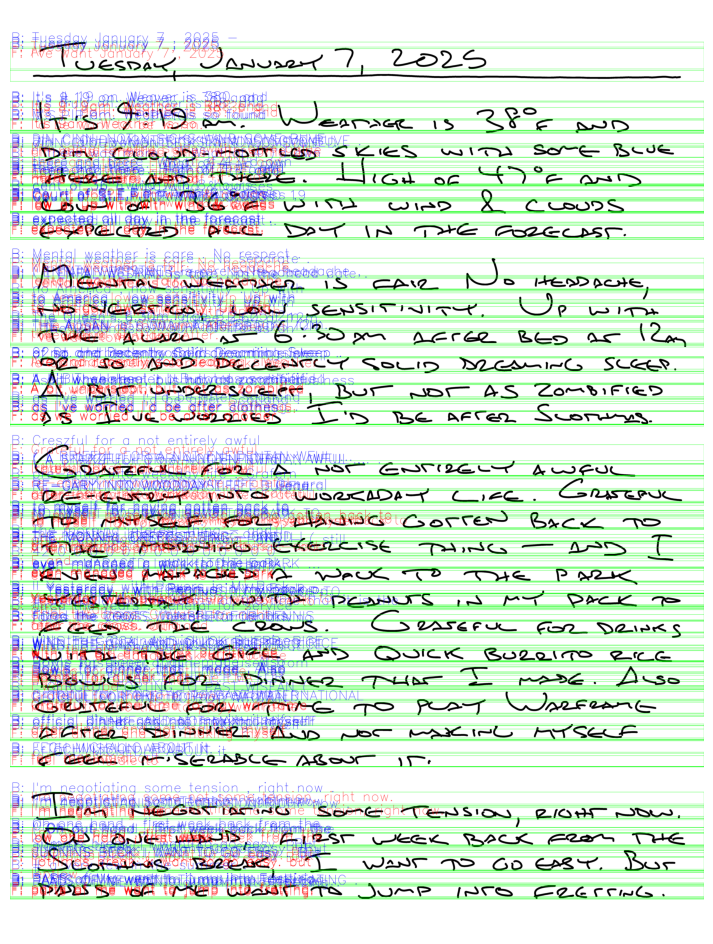

✅ Annotated comparison image saved as 'comparison_journal.png'


In [81]:

# **Step 5: Annotate the Image with Recognized Text**
annotated_image = image.copy()

for i, line_box in enumerate(line_boxes):
    x1, y1, x2, y2 = line_box

    # Draw bounding box
    cv2.rectangle(annotated_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Draw baseline model output (blue)
    baseline_text = baseline_outputs[i]
    cv2.putText(annotated_image, f"B: {baseline_text}", (x1 + 10, y1 + 0), cv2.FONT_HERSHEY_SIMPLEX, 5, (255, 0, 0), 2, cv2.LINE_AA)

    # Draw fine-tuned model output (red)
    finetuned_text = finetuned_outputs[i]
    cv2.putText(annotated_image, f"F: {finetuned_text}", (x1 + 10, y1 + 100), cv2.FONT_HERSHEY_SIMPLEX, 5, (0, 0, 255), 2, cv2.LINE_AA)

    print(f"B: {baseline_text}")
    print(f"F: {finetuned_text}")

# **Step 6: Save & Display the Annotated Image**
cv2.imwrite(OUTPUT_IMAGE_PATH, annotated_image)

# Show the annotated image
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

print(f"✅ Annotated comparison image saved as '{OUTPUT_IMAGE_PATH}'")

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.10/dist-packages/transformers/generation/utils.py:1220: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


📊 **Baseline vs. Fine-Tuned Metrics:**
🔹 Character Error Rate (CER): 0.4509
🔹 Word Error Rate (WER): 0.7500
B: Tuesday January 7 , 2025
F: Tuesday 7, 2025
B: Tuesday January 7 , 2ONS 0 -
F: Tuesday January 7 , 2025
B: It's 9.19 on. Weaver is 38. and
F: It's 9:19am. Weather is 38°F and
B: It's truly an. Weander is 38. and
F: It's 9:19am. Weather is 38°F and
B: IT'S 7.19 and Weaver is 3/8" and
F: It's 7:19am. Weather is "
B: it's 7.19 and because is she and
F: It's 7:am. Weather is 68°F and
B: it's , I.I am. Weather is so found
F: It's 9am. Weather is so
B: DIN CLOUD-MONLEY SKIES WINS SOME BUVE
F: dim cloud-mottled skies with some blue
B: din Clough-ported skies with some blue
F: dim cloud-mottled skies with some blue
B: 7din Clough-mortled skilled wind soft blue .
F: dim cloud-mottled skies with some dive
B: with clown-mortley's eyes with some ones
F: I'm low-mottled skies with the one
B: there and there . What of 4 )'d own
F: here and there. High of 47°F and
B: there and here . What of

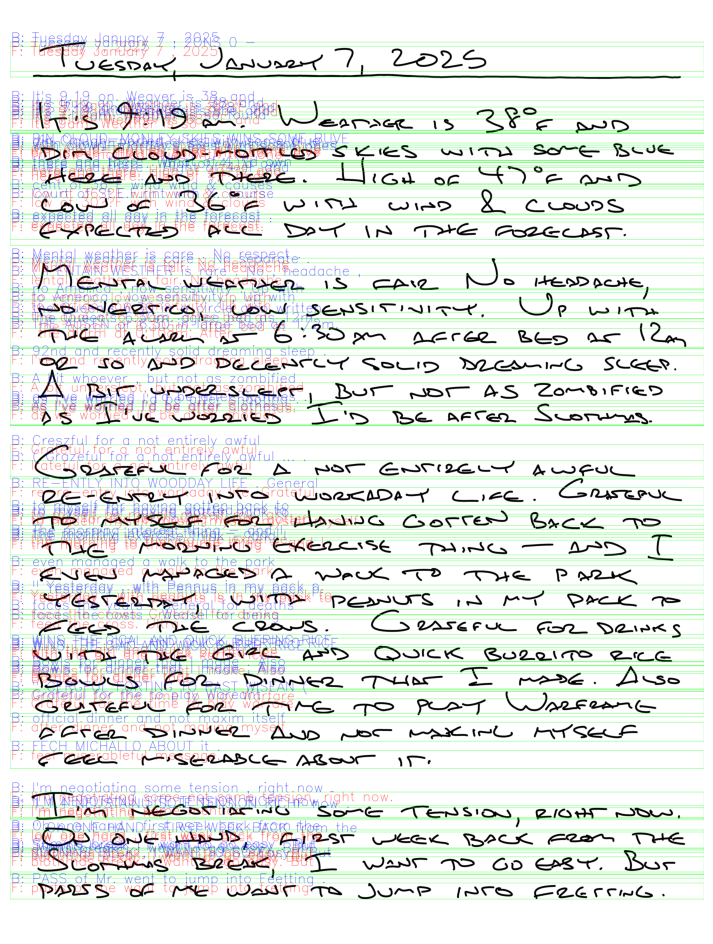

✅ Annotated comparison image saved as 'comparison_journal.png'


In [83]:
import torch
import os
import cv2
import pytesseract
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
import evaluate

# **PARAMETERS**
BASELINE_MODEL_PATH = "microsoft/trocr-base-handwritten"  # Hugging Face baseline model
FINETUNED_MODEL_PATH = "./trocr_finetuned_attempt_1"  # Your fine-tuned model directory
JOURNAL_PAGE_PATH = "my_journal_page_thresholded.png"  # The full journal page PNG
OUTPUT_IMAGE_PATH = "comparison_journal.png"  # Where the annotated image will be saved

# **Step 1: Load Both Models**
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load baseline model
processor_baseline = TrOCRProcessor.from_pretrained(BASELINE_MODEL_PATH)
model_baseline = VisionEncoderDecoderModel.from_pretrained(BASELINE_MODEL_PATH).to(device)

# Load fine-tuned model
processor_finetuned = TrOCRProcessor.from_pretrained(FINETUNED_MODEL_PATH)
model_finetuned = VisionEncoderDecoderModel.from_pretrained(FINETUNED_MODEL_PATH).to(device)

# **Step 2: Detect Words Using Tesseract and Consolidate into Lines**
def detect_lines_with_tesseract(image):
    """Detects word bounding boxes using Tesseract and consolidates them into full-width line boxes."""

    # Convert to grayscale and apply thresholding
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    binary = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 2)

    # Get word bounding boxes from Tesseract
    d = pytesseract.image_to_data(binary, output_type=pytesseract.Output.DICT)
    word_boxes = []

    for i in range(len(d["text"])):
        if d["text"][i].strip():  # Ignore empty detections
            x, y, w, h = d["left"][i], d["top"][i], d["width"][i], d["height"][i]
            word_boxes.append((x, y, x + w, y + h))

    # Consolidate words into lines
    word_boxes = sorted(word_boxes, key=lambda b: (b[1], b[0]))  # Sort by Y then X position
    line_boxes = []
    current_line = []

    for word in word_boxes:
        x1, y1, x2, y2 = word
        if not current_line:
            current_line.append(word)
            continue

        # Check if the new word belongs to the same line (Y-overlap allowed)
        last_x1, last_y1, last_x2, last_y2 = current_line[-1]
        if abs(y1 - last_y1) <= 20:  # Allow some vertical tolerance
            current_line.append(word)
        else:
            # Convert current line into a full-width bounding box
            min_x = min([b[0] for b in current_line])
            max_x = max([b[2] for b in current_line])
            min_y = min([b[1] for b in current_line])
            max_y = max([b[3] for b in current_line])
            line_boxes.append((0, min_y, image.shape[1], max_y))  # Full-width box

            current_line = [word]  # Start new line

    # Convert last remaining words into a line box
    if current_line:
        min_x = min([b[0] for b in current_line])
        max_x = max([b[2] for b in current_line])
        min_y = min([b[1] for b in current_line])
        max_y = max([b[3] for b in current_line])
        line_boxes.append((0, min_y, image.shape[1], max_y))

    return sorted(line_boxes, key=lambda b: b[1])  # Sort lines top-to-bottom

# **Load the journal page and detect lines**
image = cv2.imread(JOURNAL_PAGE_PATH)

# Ensure the image loads properly
if image is None:
    raise FileNotFoundError(f"❌ Error: Could not load the image file '{JOURNAL_PAGE_PATH}'. Check the file path!")

line_boxes = detect_lines_with_tesseract(image)

# **Step 3: Run Both Models on Each Line**
def recognize_text_from_line(image, line_box, processor, model):
    """Runs OCR on a cropped line from the journal page."""
    x1, y1, x2, y2 = line_box
    cropped_line = image[y1:y2, x1:x2]
    cropped_pil = Image.fromarray(cv2.cvtColor(cropped_line, cv2.COLOR_BGR2RGB))

    # Run TrOCR
    pixel_values = processor(cropped_pil, return_tensors="pt").pixel_values.to(device)
    with torch.no_grad():
        generated_ids = model.generate(pixel_values)

    return processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

baseline_outputs = []
finetuned_outputs = []

for line_box in line_boxes:
    baseline_text = recognize_text_from_line(image, line_box, processor_baseline, model_baseline)
    finetuned_text = recognize_text_from_line(image, line_box, processor_finetuned, model_finetuned)

    baseline_outputs.append(baseline_text)
    finetuned_outputs.append(finetuned_text)

# **Step 4: Compute CER & WER Using `evaluate` Library**
cer_metric = evaluate.load("cer")
wer_metric = evaluate.load("wer")

cer_baseline = cer_metric.compute(predictions=baseline_outputs, references=finetuned_outputs)
wer_baseline = wer_metric.compute(predictions=baseline_outputs, references=finetuned_outputs)

print(f"📊 **Baseline vs. Fine-Tuned Metrics:**")
print(f"🔹 Character Error Rate (CER): {cer_baseline:.4f}")
print(f"🔹 Word Error Rate (WER): {wer_baseline:.4f}")

# **Step 5: Annotate the Image with Recognized Text**
annotated_image = image.copy()

for i, line_box in enumerate(line_boxes):
    x1, y1, x2, y2 = line_box

    # Draw bounding box
    cv2.rectangle(annotated_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Draw baseline model output (blue)
    baseline_text = baseline_outputs[i]
    cv2.putText(annotated_image, f"B: {baseline_text}", (x1 + 10, y1 + 0), cv2.FONT_HERSHEY_SIMPLEX, 5, (255, 0, 0), 2, cv2.LINE_AA)

    # Draw fine-tuned model output (red)
    finetuned_text = finetuned_outputs[i]
    cv2.putText(annotated_image, f"F: {finetuned_text}", (x1 + 10, y1 + 100), cv2.FONT_HERSHEY_SIMPLEX, 5, (0, 0, 255), 2, cv2.LINE_AA)

    print(f"B: {baseline_text}")
    print(f"F: {finetuned_text}")

# **Step 6: Save & Display the Annotated Image**
cv2.imwrite(OUTPUT_IMAGE_PATH, annotated_image)

# Show the annotated image
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

print(f"✅ Annotated comparison image saved as '{OUTPUT_IMAGE_PATH}'")
